# Exploración SECOP II: ¿se puede predecir si un contrato termina con adición?

Spike de factibilidad de datos (no es el proyecto final). Todo el análisis de este notebook es **local**: trabaja sobre muestras ya descargadas de datos.gov.co (carpeta `data/raw/`) y sobre agregados poblacionales guardados en `data/raw/meta/`. No hace ninguna consulta a la red.

Cada afirmación se marca como **[VERIFICADO]** (lo vimos en los datos) o **[SUPUESTO]**.

**Cómo se obtuvieron los datos** (código en `secop_descarga.py`, no se vuelve a ejecutar aquí):
- Contratos (`jbjy-vk9h`): 211.997 contratos, hasta 2.000 por mes de firma (enero 2018 a octubre 2026), repartidos en 4 ventanas dentro de cada mes. Sin columnas con datos personales.
- Procesos (`p6dx-8zbt`), Adiciones (`cb9c-h8sn`) y Ejecución (`mfmm-jqmq`): solo las filas ligadas a esos contratos, en lotes de 150 IDs. Adiciones y Ejecución se agregaron en el servidor a una fila por contrato.
- Modificaciones (`u8cx-r425`): submuestra de 3.000 contratos (2022-2024), solo para explorar.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

DATA = Path("data/raw")
META = DATA / "meta"
FECHA_CORTE = pd.Timestamp("2026-10-14")   # fecha en la que se hizo la descarga
SEED = 42
proc = psutil.Process()


def ram(etiqueta):
    mi = proc.memory_info()
    pico = getattr(mi, "peak_wset", mi.rss)
    aviso = "  <-- SUPERA 6 GB" if pico / 1e6 > 6000 else ""
    print(f"[RAM] {etiqueta}: actual {mi.rss / 1e6:.0f} MB | pico {pico / 1e6:.0f} MB{aviso}")


ram("inicio")

[RAM] inicio: actual 137 MB | pico 137 MB


## 1. Metadata de los datasets

Además de los 3 datasets pedidos, el catálogo de datos.gov.co tiene dos que sirven para la etiqueta: **Adiciones** (`cb9c-h8sn`) y **Modificaciones a contratos** (`u8cx-r425`).

In [2]:
import json

resumen_ds = pd.read_csv(META / "resumen_datasets.csv")
display(resumen_ds)

meta = {r.dataset: json.loads((META / f"{r.id}.json").read_text(encoding="utf-8")) for r in resumen_ds.itertuples()}
cols_contratos = pd.DataFrame({
    "columna": [c["fieldName"] for c in meta["contratos"]["columns"]],
    "tipo": [c["dataTypeName"] for c in meta["contratos"]["columns"]],
})
print("Tipos de columna en Contratos:", cols_contratos.tipo.value_counts().to_dict())
cols_num = cols_contratos.loc[cols_contratos.tipo == "number", "columna"].tolist()
cols_fecha = cols_contratos.loc[cols_contratos.tipo == "calendar_date", "columna"].tolist()

,dataset,id,columnas,filas,columna_fecha,desde,hasta
0,contratos,jbjy-vk9h,95,5628779,fecha_de_firma,2015-06-11,2026-10-13
1,procesos,p6dx-8zbt,59,9319102,fecha_de_publicacion_del,2015-04-16,2026-10-13
2,ejecucion,mfmm-jqmq,16,4831061,fechacreacion,2015-11-10,2026-10-14
3,adiciones,cb9c-h8sn,5,8342247,fecharegistro,2015-09-12,2026-10-13
4,modificaciones,u8cx-r425,35,29812796,fecha_creacion,2015-09-12,2026-10-14


Tipos de columna en Contratos: {'text': 64, 'number': 19, 'calendar_date': 11, 'url': 1}


**[VERIFICADO]** Contratos tiene 5,6 M de filas (2015-2026), Procesos 9,3 M, Ejecución 4,8 M, Adiciones 8,3 M y Modificaciones 29,8 M (muchas son versiones de una misma modificación).

## 2. Variable objetivo: candidatas

Columnas relacionadas con adiciones que **sí existen** (nombres tomados de la metadata):

| Dataset | Columna | Qué es |
|---|---|---|
| Contratos | `dias_adicionados` | días adicionados al contrato (solo tiempo) |
| Contratos | `valor_del_contrato` | valor total (¿ya incluye adiciones?) |
| Adiciones | `tipo` | un evento por modificación (`Adicion en el valor`, `Extension`, `Modificacion General`, ...) |
| Modificaciones | `valor_modificacion`, `dias_extendidos` | por versión de modificación |

En Contratos **no existe** una columna de "valor adicionado". Con la población completa (agregados guardados en `meta/`) se ve cómo se comporta `dias_adicionados` y qué fracción de contratos ya pasó su fecha de fin.

In [3]:
pob = pd.read_csv(META / "poblacion_contratos_por_anio.csv")
pob = pob[pob.anio != "sin_fecha_de_firma"].copy()
pob["anio"] = pob.anio.astype(int)
pob["tasa_dias_adicionados"] = pob.con_dias_adicionados / pob.n
display(pob.set_index("anio")[["n", "tasa_dias_adicionados", "pct_fin_pasada", "pct_fin_futura"]].round(3))

,n,tasa_dias_adicionados,pct_fin_pasada,pct_fin_futura
anio,,,,
2015,10,0.000,1.000,0.000
2016,1340,0.001,0.999,0.001
2017,22224,0.002,1.000,0.000
2018,142586,0.008,0.999,0.001
2019,142090,0.111,1.000,0.000
2020,356623,0.131,0.999,0.001
2021,560441,0.097,0.998,0.002
2022,707765,0.095,0.997,0.003
2023,835462,0.128,0.996,0.004


**[VERIFICADO]** Sobre la población completa de Contratos (5,56 M con fecha de firma; otros 67 mil no tienen fecha de firma):

- `dias_adicionados` es casi siempre 0 en 2016-2018 y recién desde 2019 tiene valores (~10-13 %): antes de 2019 la columna no se diligenciaba, así que esos años no sirven para entrenar.
- La tasa **no cae** en los años recientes, **sube** (20 % en 2025, 24 % en 2026). Eso es lo contrario de lo que produciría la censura (se discute en la sección 6).

## 3. Muestra de Contratos

- Estratificada por **mes de firma**: hasta 2.000 contratos por mes, en 4 ventanas dentro del mes (días 1-7, 8-14, 15-21, 22-fin) proporcionales al volumen de cada ventana.
- Dentro de cada ventana no se usó `$order + $limit` (sesga hacia el inicio): se filtró por el último dígito de `id_contrato` y se submuestreó con semilla fija.
- 21 columnas con datos personales (representante legal, supervisor, ordenador del gasto, cuenta bancaria, documento del proveedor) **no se descargaron**.
- **No se guardó** el conteo poblacional por mes (se usó para repartir las cuotas y no se persistió); aquí solo se reporta el conteo de la muestra.

contratos: (211997, 76) | RAM del DataFrame: 361 MB
meses: 106 | por mes: min 1999 mediana 2000 max 2000
meses con menos de 2000: {Period('2022-11', 'M'): 1999, Period('2022-12', 'M'): 1999, Period('2024-07', 'M'): 1999}


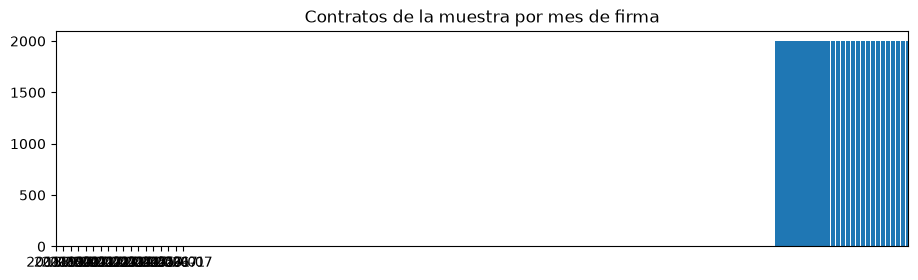

anio,2018,2019,2020,2021,2022,2023,2024,2025,2026
contratos_en_muestra,24000,24000,24000,24000,23998,24000,23999,24000,20000


[RAM] contratos cargados: actual 831 MB | pico 834 MB


In [4]:
contratos = pd.read_parquet(DATA / "contratos_muestra.parquet")
for c in cols_num:
    if c in contratos:
        contratos[c] = pd.to_numeric(contratos[c], errors="coerce")
for c in cols_fecha:
    if c in contratos:
        contratos[c] = pd.to_datetime(contratos[c], errors="coerce")
assert contratos.id_contrato.is_unique
contratos["anio"] = contratos.fecha_de_firma.dt.year
contratos["mes"] = contratos.fecha_de_firma.dt.to_period("M")
print("contratos:", contratos.shape, "| RAM del DataFrame:", round(contratos.memory_usage(deep=True).sum() / 1e6), "MB")
por_mes = contratos.groupby("mes").size()
print("meses:", len(por_mes), "| por mes: min", por_mes.min(), "mediana", int(por_mes.median()), "max", por_mes.max())
print("meses con menos de 2000:", por_mes[por_mes < 2000].to_dict())
fig, ax = plt.subplots(figsize=(11, 2.8))
por_mes.plot(ax=ax, kind="bar", width=0.9)
ax.set_xticks(range(0, len(por_mes), 6)); ax.set_xticklabels([str(m) for m in por_mes.index[::6]], rotation=0)
ax.set_title("Contratos de la muestra por mes de firma"); ax.set_xlabel("")
plt.show()
display(contratos.groupby("anio").size().to_frame("contratos_en_muestra").T)
ram("contratos cargados")

## 4. Llaves y joins

| Unión | Llave en Contratos | Llave en el otro dataset |
|---|---|---|
| Contratos -> Procesos | `proceso_de_compra` (`CO1.BDOS...`) | `id_del_portafolio` (`id_del_proceso` da 0 coincidencias) |
| Contratos -> Adiciones | `id_contrato` (`CO1.PCCNTR...`) | `id_contrato` |
| Contratos -> Modificaciones | `id_contrato` | `id_contrato` |
| Contratos -> Ejecución | `id_contrato` | `identificadorcontrato` |

In [5]:
procesos = pd.read_parquet(DATA / "procesos_muestra.parquet")
adiciones = pd.read_parquet(DATA / "adiciones_agregadas.parquet")
ejecucion = pd.read_parquet(DATA / "ejecucion_agregada.parquet")
modif = pd.read_parquet(DATA / "modificaciones_submuestra.parquet")
for c in ["n_eventos", "n_adic_valor", "n_extension", "n_mod_general"]:
    adiciones[c] = pd.to_numeric(adiciones[c])
adiciones["n_otros"] = adiciones.n_eventos - adiciones.n_adic_valor - adiciones.n_extension - adiciones.n_mod_general
ejecucion["n_filas_ejec"] = pd.to_numeric(ejecucion.n_filas_ejec)
ejecucion["avance_real_max"] = pd.to_numeric(ejecucion.avance_real_max, errors="coerce")
for c in ["valor_modificacion", "dias_extendidos", "numero_version"]:
    modif[c] = pd.to_numeric(modif[c], errors="coerce")
print("filas -> procesos:", len(procesos), "| adiciones (agregado por contrato):", len(adiciones),
      "| ejecucion (agregado por contrato):", len(ejecucion), "| modificaciones (submuestra):", len(modif))
ram("datasets unidos cargados")

filas -> procesos: 348580 | adiciones (agregado por contrato): 150295 | ejecucion (agregado por contrato): 26618 | modificaciones (submuestra): 13684
[RAM] datasets unidos cargados: actual 1006 MB | pico 1011 MB


### 4a. Adiciones: qué compone el 71 % de contratos con algún evento

El agregado en el servidor separó tres tipos (`Adicion en el valor`, `Extension`, `Modificacion General`) y dejó el resto en **otros**. Ese resto no se pudo desglosar más porque ya no se hacen consultas; sí se puede ver su peso con el conteo poblacional de eventos por tipo guardado en `meta/`.

In [6]:
ev_pob = pd.read_csv(META / "poblacion_adiciones_eventos_por_tipo.csv")
ev_pob["pct_eventos"] = (ev_pob.n_eventos / ev_pob.n_eventos.sum() * 100).round(2)
print("Eventos por tipo en TODO el dataset de Adiciones (poblacion):")
display(ev_pob)

Eventos por tipo en TODO el dataset de Adiciones (poblacion):


,tipo,n_eventos,pct_eventos
0,Modificacion General,4049723,48.54
1,Conclusion,2022445,24.24
2,No definido,1640768,19.67
3,Adicion en el valor,256350,3.07
4,Reactivacion,139897,1.68
5,Suspension,125953,1.51
6,Cesion,106587,1.28
7,Extension,380,0.00
8,Reduccion en el valor,143,0.00
9,Expiracion,1,0.00


In [7]:
a = contratos[["id_contrato", "anio"]].merge(adiciones, on="id_contrato", how="left")
tipos_ev = {"adicion en valor": "n_adic_valor", "extension (tiempo)": "n_extension",
            "modificacion general": "n_mod_general", "otros (conclusion, no definido, suspension, cesion...)": "n_otros"}
filas = []
for etiqueta, col in tipos_ev.items():
    filas.append({"tipo": etiqueta, "eventos_en_muestra": int(a[col].sum()),
                  "pct_contratos_con_ge1": round((a[col].fillna(0) > 0).mean() * 100, 1)})
filas.append({"tipo": "CUALQUIER evento", "eventos_en_muestra": int(a.n_eventos.sum()),
              "pct_contratos_con_ge1": round(a.n_eventos.notna().mean() * 100, 1)})
display(pd.DataFrame(filas))

print("\n% de contratos con >=1 evento de cada tipo, por anio de firma:")
por_anio = pd.DataFrame({etiqueta: (a[col].fillna(0) > 0).groupby(a.anio).mean() * 100 for etiqueta, col in tipos_ev.items()})
por_anio["cualquier evento"] = a.n_eventos.notna().groupby(a.anio).mean() * 100
display(por_anio.round(1))

,tipo,eventos_en_muestra,pct_contratos_con_ge1
0,adicion en valor,18182,6.7
1,extension (tiempo),0,0.0
2,modificacion general,180227,36.1
3,"otros (conclusion, no definido, suspension, cesion...)",162099,53.5
4,CUALQUIER evento,360508,70.9



% de contratos con >=1 evento de cada tipo, por anio de firma:


,adicion en valor,extension (tiempo),modificacion general,"otros (conclusion, no definido, suspension, cesion...)",cualquier evento
anio,,,,,
2018,16.1,0.0,37.3,49.5,72.4
2019,18.2,0.0,41.7,56.7,77.7
2020,6.8,0.0,40.4,64.2,79.6
2021,3.3,0.0,36.5,67.8,80.5
2022,5.1,0.0,39.7,65.2,79.9
2023,3.3,0.0,35.4,59.2,74.0
2024,2.3,0.0,34.2,58.5,73.5
2025,2.2,0.0,34.8,44.7,64.7
2026,1.8,0.0,22.8,7.8,28.8


**[VERIFICADO]** El 71 % se explica sobre todo por eventos administrativos:

- En todo el dataset, `Conclusion` (24 %) y `No definido` (20 %) son el 44 % de los eventos, y `Modificacion General` otro 49 %. Las **adiciones de valor son solo el 3 %** de los eventos.
- En la muestra, el 53 % de los contratos tiene al menos un evento "otros" (cierres de expediente, actas de liquidación), el 36 % tiene una `Modificacion General` y solo el ~7 % tiene una `Adicion en el valor`.
- `Extension` casi no se usa (380 eventos en 8,3 M; **cero** en la muestra): las prórrogas no se registran con ese tipo. El tiempo adicionado vive en `dias_adicionados` o dentro de `Modificacion General`.

**Consecuencia**: "tiene algún evento en Adiciones" **no** sirve como etiqueta. `Modificacion General` tampoco se puede usar tal cual porque mezcla adiciones con cambios de otro tipo (el campo `descripcion` lo distinguiría, pero no se descargó). Las etiquetas candidatas quedan en `dias_adicionados > 0` (tiempo) y `Adicion en el valor` (valor).

### 4b. Procesos: por qué hay ~1,7 filas por portafolio y regla de deduplicación

In [8]:
procesos["fecha_adjudicacion"] = pd.to_datetime(procesos.fecha_adjudicacion, errors="coerce")
procesos["fecha_de_publicacion_del"] = pd.to_datetime(procesos.fecha_de_publicacion_del, errors="coerce")
for c in ["precio_base", "duracion", "valor_total_adjudicacion", "numero_de_lotes", "proveedores_invitados",
          "proveedores_con_invitacion", "visualizaciones_del", "proveedores_que_manifestaron",
          "respuestas_al_procedimiento", "respuestas_externas", "conteo_de_respuestas_a_ofertas", "proveedores_unicos_con"]:
    procesos[c] = pd.to_numeric(procesos[c], errors="coerce")

n_portafolios_pedidos = contratos.proceso_de_compra.nunique()
n_portafolios = procesos.id_del_portafolio.nunique()
n_req = procesos.id_del_proceso.nunique()
filas_extra = len(procesos) - n_portafolios
print(f"portafolios pedidos: {n_portafolios_pedidos} | con alguna fila en Procesos: {n_portafolios} ({n_portafolios / n_portafolios_pedidos:.1%})")
print(f"filas: {len(procesos)} | procesos distintos (id_del_proceso): {n_req} | filas por portafolio: {len(procesos) / n_portafolios:.2f}")
extra_repetidas = len(procesos) - n_req
extra_req = n_req - n_portafolios
print(f"filas 'sobrantes' (sobre 1 por portafolio): {filas_extra}")
print(f"  - mismas filas de un MISMO proceso repetido (una por adjudicacion/lote): {extra_repetidas} ({extra_repetidas / filas_extra:.0%})")
print(f"  - procesos adicionales dentro del mismo portafolio: {extra_req} ({extra_req / filas_extra:.0%})")

n_fil = procesos.groupby("id_del_portafolio").size()
print("distribucion de filas por portafolio:", n_fil.value_counts().sort_index().head(8).to_dict())
multi = procesos[procesos.id_del_portafolio.isin(n_fil[n_fil > 1].index)]
var = {c: (multi.groupby("id_del_portafolio")[c].nunique(dropna=False) > 1).mean()
       for c in procesos.columns if c != "id_del_portafolio"}
print("\n% de portafolios con varias filas en los que cada columna cambia:")
display(pd.Series(var).sort_values(ascending=False).round(3).head(12).to_frame("pct_portafolios"))
print("adjudicado:", procesos.adjudicado.value_counts().to_dict())
ejemplo = multi.id_del_portafolio.drop_duplicates().iloc[[0, 5]]
display(multi[multi.id_del_portafolio.isin(ejemplo)].sort_values("id_del_portafolio")[
    ["id_del_portafolio", "id_del_proceso", "adjudicado", "estado_del_procedimiento", "fecha_adjudicacion", "valor_total_adjudicacion", "numero_de_lotes"]])

portafolios pedidos: 202002 | con alguna fila en Procesos: 201639 (99.8%)
filas: 348580 | procesos distintos (id_del_proceso): 219603 | filas por portafolio: 1.73
filas 'sobrantes' (sobre 1 por portafolio): 146941
  - mismas filas de un MISMO proceso repetido (una por adjudicacion/lote): 128977 (88%)
  - procesos adicionales dentro del mismo portafolio: 17964 (12%)
distribucion de filas por portafolio: {1: 185391, 2: 7593, 3: 5226, 4: 858, 5: 471, 6: 358, 7: 129, 8: 101}



% de portafolios con varias filas en los que cada columna cambia:


,pct_portafolios
valor_total_adjudicacion,0.852
estado_resumen,0.845
fecha_adjudicacion,0.810
id_del_proceso,0.784
estado_del_procedimiento,0.784
fecha_de_publicacion_del,0.779
fase,0.773
respuestas_al_procedimiento,0.767
proveedores_unicos_con,0.765
adjudicado,0.749


adjudicado: {'No': 177352, 'Si': 171228}


,id_del_portafolio,id_del_proceso,adjudicado,estado_del_procedimiento,fecha_adjudicacion,valor_total_adjudicacion,numero_de_lotes
0,CO1.BDOS.162422,CO1.REQ.170617,Si,Seleccionado,2017-06-07,48000000,4
1,CO1.BDOS.162422,CO1.REQ.165422,No,Evaluación,NaT,0,4
2,CO1.BDOS.162422,CO1.REQ.170617,Si,Seleccionado,2017-06-07,34167525,4
3,CO1.BDOS.162422,CO1.REQ.169405,No,Evaluación,NaT,0,4
4,CO1.BDOS.162422,CO1.REQ.170617,Si,Seleccionado,2017-06-07,50645000,4
1064,CO1.BDOS.220119,CO1.REQ.230236,Si,Abierto,2017-10-27,300000000,3
1065,CO1.BDOS.220119,CO1.REQ.230236,Si,Abierto,2017-10-27,300000000,3
1066,CO1.BDOS.220119,CO1.REQ.226115,No,Evaluación,NaT,0,3
1067,CO1.BDOS.220119,CO1.REQ.230236,Si,Abierto,2017-10-27,100000000,3
1068,CO1.BDOS.220119,CO1.REQ.230236,Si,Abierto,2017-10-27,100000000,3


**[VERIFICADO]** Hay dos causas:

1. **Filas repetidas del mismo proceso** (~88 % de las filas extra): el dataset trae una fila por adjudicación (lote o proveedor), cada una con su propio `valor_total_adjudicacion`. El resto de columnas del proceso se repite.
2. **Varios procesos (`id_del_proceso`, tipo `CO1.REQ...`) en un mismo portafolio** (~12 %): son intentos anteriores o paralelos del mismo proceso de compra; los no adjudicados aparecen en estado `Evaluación` o `Cancelado`, con valor adjudicado 0.

**Regla de deduplicación** (una fila por portafolio, decidida antes del join):

1. De los procesos del portafolio se prefiere el **adjudicado** (`adjudicado = Si`), porque es el que da lugar al contrato. Solo aplica al ~22 % de los portafolios: en el ~78 % restante ningún proceso viene marcado como adjudicado (típico de contratación directa y mínima cuantía, que no tienen adjudicación formal) y se pasa al paso 2.
2. Entre los candidatos, el de `fecha_adjudicacion` más **reciente**; si empatan o no hay fecha, el `id_del_proceso` más alto (determinista). **[SUPUESTO]** el REQ más reciente es la versión final del proceso.

Ningún portafolio tiene más de un proceso adjudicado, así que el paso 1 nunca es ambiguo (se verifica abajo).
3. Dentro del proceso elegido las filas solo difieren en el valor adjudicado: se conserva una fila y se guarda `p_n_filas` (número de adjudicaciones) y `p_valor_adjudicado_max`. `valor_total_adjudicacion` **no se usa como feature** porque con varios lotes no es el valor del contrato.

In [9]:
p = procesos.copy()
p["_adj"] = (p.adjudicado == "Si").astype(int)
p["_req_num"] = pd.to_numeric(p.id_del_proceso.str.extract(r"(\d+)$")[0], errors="coerce")
orden = p.sort_values(["id_del_portafolio", "_adj", "fecha_adjudicacion", "_req_num"],
                      ascending=[True, False, False, False], na_position="last")
elegido = orden.drop_duplicates("id_del_portafolio")[["id_del_portafolio", "id_del_proceso"]]
p_sel = p.merge(elegido, on=["id_del_portafolio", "id_del_proceso"], how="inner")

n_adj_req = p[p._adj == 1].groupby("id_del_portafolio").id_del_proceso.nunique()
print("portafolios con >1 proceso adjudicado (ambiguos):", int((n_adj_req > 1).sum()), f"({(n_adj_req > 1).sum() / n_portafolios:.2%})")
print("portafolios sin ningun proceso adjudicado:", int(n_portafolios - len(n_adj_req)), f"({(n_portafolios - len(n_adj_req)) / n_portafolios:.1%})")

# verificar que dentro del proceso elegido solo cambia el valor adjudicado
cols_chk = [c for c in procesos.columns if c not in {"id_del_portafolio", "id_del_proceso", "valor_total_adjudicacion"}]
dentro = p_sel.groupby("id_del_portafolio")[cols_chk].nunique(dropna=False).gt(1).mean().sort_values(ascending=False)
print("\n% de portafolios en los que la columna aun varia dentro del proceso elegido:")
display(dentro.head(6).round(4).to_frame("pct"))

p_n = p_sel.groupby("id_del_portafolio").size().rename("n_filas")
p_val = p_sel.groupby("id_del_portafolio").valor_total_adjudicacion.max().rename("valor_adjudicado_max")
procesos_1 = (p_sel.drop_duplicates("id_del_portafolio").drop(columns=["_adj", "_req_num", "valor_total_adjudicacion"])
              .set_index("id_del_portafolio").join(p_n).join(p_val).reset_index().add_prefix("p_"))
assert procesos_1.p_id_del_portafolio.is_unique
print("\nprocesos tras la regla:", len(procesos_1), "filas (una por portafolio)")

portafolios con >1 proceso adjudicado (ambiguos): 0 (0.00%)
portafolios sin ningun proceso adjudicado: 157136 (77.9%)



% de portafolios en los que la columna aun varia dentro del proceso elegido:


,pct
fecha_adjudicacion,0.0079
estado_resumen,0.0077
unidad_de_duracion,0.0000
fecha_de_publicacion_del,0.0000
precio_base,0.0000
duracion,0.0000



procesos tras la regla: 201639 filas (una por portafolio)


In [10]:
n0 = len(contratos)
d = (contratos
     .merge(procesos_1, left_on="proceso_de_compra", right_on="p_id_del_portafolio", how="left")
     .merge(adiciones, on="id_contrato", how="left")
     .merge(ejecucion, on="id_contrato", how="left"))
assert len(d) == n0 and d.id_contrato.is_unique, "el join cambio el numero de contratos"
print(f"contratos antes del join: {n0} | despues: {len(d)} | id_contrato unico: {d.id_contrato.is_unique}")
print(f"contratos con proceso: {d.p_id_del_portafolio.notna().mean():.1%} | con proceso adjudicado: {(d.p_adjudicado == 'Si').mean():.1%}")
d["en_procesos"] = d.p_id_del_portafolio.notna()
d["en_ejecucion"] = d.n_filas_ejec.notna()
d["en_adiciones"] = d.n_eventos.notna()
display(d.groupby("anio").agg(n=("id_contrato", "size"), pct_en_procesos=("en_procesos", "mean"),
                              pct_en_adiciones=("en_adiciones", "mean"), pct_en_ejecucion=("en_ejecucion", "mean")).round(3))
ram("tras los joins")

contratos antes del join: 211997 | despues: 211997 | id_contrato unico: True
contratos con proceso: 99.8% | con proceso adjudicado: 21.6%


,n,pct_en_procesos,pct_en_adiciones,pct_en_ejecucion
anio,,,,
2018,24000,1.000,0.724,0.183
2019,24000,1.000,0.777,0.192
2020,24000,1.000,0.796,0.129
2021,24000,1.000,0.805,0.132
2022,23998,1.000,0.799,0.116
2023,24000,1.000,0.740,0.114
2024,23999,0.996,0.735,0.099
2025,24000,0.995,0.647,0.095
2026,20000,0.992,0.288,0.058


[RAM] tras los joins: actual 1656 MB | pico 1676 MB


### 4c. Ejecución: por qué solo el 12,6 % hace match y si es información posterior a la firma

In [11]:
print("columnas del dataset Ejecucion (metadata):")
cols_ej = pd.DataFrame({"columna": [c["fieldName"] for c in meta["ejecucion"]["columns"]],
                        "descripcion": [(c.get("description") or "")[:100] for c in meta["ejecucion"]["columns"]]})
post = {"fechadeentregaesperada", "porcentajedeavanceesperado", "fechadeentregareal", "porcentaje_de_avance_real",
        "estado_del_contrato", "cantidadrecibida", "cantidadporrecibir", "fechacreacion"}
cols_ej["se_conoce_despues_de_firmar"] = cols_ej.columna.isin(post)
display(cols_ej)

print("\n% de contratos presentes en Ejecucion, por anio de firma, modalidad y tipo (solo grupos con >1.500 contratos):")
t_mod = d.groupby("modalidad_de_contratacion").agg(n=("en_ejecucion", "size"), pct_en_ejecucion=("en_ejecucion", "mean")).query("n > 1500")
t_tipo = d.groupby("tipo_de_contrato").agg(n=("en_ejecucion", "size"), pct_en_ejecucion=("en_ejecucion", "mean")).query("n > 1500")
display(d.groupby("anio").en_ejecucion.mean().round(3).to_frame("pct_en_ejecucion").T)
display(t_mod.sort_values("pct_en_ejecucion").round(3))
display(t_tipo.sort_values("pct_en_ejecucion").round(3))
d["y_dias_tmp"] = (d.dias_adicionados > 0).astype(int)
print("\ntasa de dias_adicionados>0 en contratos CON registro en Ejecucion:", round(d[d.en_ejecucion].y_dias_tmp.mean(), 3),
      "| SIN registro:", round(d[~d.en_ejecucion].y_dias_tmp.mean(), 3))
print("contratos en Ejecucion: mediana de filas de plan por contrato:", ejecucion.n_filas_ejec.median(), "| avance real maximo, mediana:", ejecucion.avance_real_max.median())
d = d.drop(columns="y_dias_tmp")

columnas del dataset Ejecucion (metadata):


,columna,descripcion,se_conoce_despues_de_firmar
0,identificadorcontrato,Enlaza el plan de ejecucion con el contrato correspondiente,False
1,tipoejecucion,Determina si el plan se reporta en términos de entregables o de porcentaje de avance,False
2,nombreplan,"Nombre del Plan de Ejecucion del contrato, refiere al identificador unico con el que se crea la prog",False
3,fechadeentregaesperada,Fecha de Entrega esperada del ultimo entregable registrado en el plan de avance,True
4,porcentajedeavanceesperado,Porcentaje de avance esperado para el proyecto a la fecha,True
5,fechadeentregareal,Fecha de Entrega real del ultimo entregable registrado en el plan de avance,True
6,porcentaje_de_avance_real,Porcentaje de ejecución real del proyecto,True
7,estado_del_contrato,Estado de la ejecución del contrato,True
8,referencia_de_articulos,Referencia de los articulos de la ejecución del contrato,False
9,descripci_n,Descripción de la ejecución del contrato,False



% de contratos presentes en Ejecucion, por anio de firma, modalidad y tipo (solo grupos con >1.500 contratos):


anio,2018,2019,2020,2021,2022,2023,2024,2025,2026
pct_en_ejecucion,0.183,0.192,0.129,0.132,0.116,0.114,0.099,0.095,0.058


,n,pct_en_ejecucion
modalidad_de_contratacion,,
Contratación régimen especial,32762,0.040
Contratación régimen especial (con ofertas),2772,0.058
Contratación directa,131731,0.123
Selección Abreviada de Menor Cuantía,5254,0.179
Contratación Directa (con ofertas),3019,0.190
Selección abreviada subasta inversa,4332,0.212
Mínima cuantía,28387,0.216


,n,pct_en_ejecucion
tipo_de_contrato,,
Decreto 092 de 2017,9035,0.041
Arrendamiento de inmuebles,1628,0.105
Obra,3526,0.110
Prestación de servicios,163145,0.119
Otro,9644,0.127
Compraventa,9982,0.219
Suministros,11463,0.231



tasa de dias_adicionados>0 en contratos CON registro en Ejecucion: 0.081 | SIN registro: 0.12
contratos en Ejecucion: mediana de filas de plan por contrato: 4.0 | avance real maximo, mediana: 100.0


**[VERIFICADO]** Ejecución tiene datos solo para el **12,6 %** de los contratos, y esa cobertura:

- **Depende de la modalidad y del tipo**: es baja en régimen especial (~4 %) y en contratos bajo el Decreto 092 de 2017 (~4 %); es más alta en mínima cuantía, compraventa y suministros (~22 %).
- **Baja con los años** (≈18-19 % en 2018-19 a ≈9,5 % en 2025 y ≈6 % en 2026).
- Los contratos presentes tienen **menos** adiciones (8 % vs 12 %): quien reporta planes de ejecución no es una muestra al azar.

**[SUPUESTO]** La causa es que el plan de ejecución es opcional (cada entidad decide si lo diligencia en SECOP II); no hay una columna que lo confirme.

**Decisión: Ejecución se descarta como fuente de features.** Sus columnas (avance real, entregas reales, cantidades recibidas, estado de ejecución, fecha de creación del registro) describen lo que pasa **durante** la ejecución, es decir, después de la firma: son fuga. Además, faltan en el 87 % de los contratos y esa ausencia no es aleatoria. En el baseline solo se usa para una variante "con fuga" que muestra cuánto inflaría las métricas.

## 5. Variable objetivo: definiciones

- **A. `y_dias`**: `dias_adicionados > 0` (Contratos). Mide solo tiempo. Los `0` son "sin adición" (la columna no tiene nulos).
- **B. `y_adic_valor`**: el contrato tiene ≥ 1 evento `Adicion en el valor` en Adiciones. Mide solo valor.
- **C. `y_cualquiera`**: A o B. Se descarta `Extension` (cero eventos) y `Modificacion General` (ambigua).
- Se probó una etiqueta de valor basada en `valor_del_contrato` vs `valor_total_adjudicacion`, pero con varios lotes el valor adjudicado no es el del contrato (sección 4b), así que no se usa.

In [12]:
d["y_dias"] = (d.dias_adicionados > 0).astype(int)
d["y_adic_valor"] = (d.n_adic_valor.fillna(0) > 0).astype(int)
d["y_cualquiera"] = ((d.y_dias == 1) | (d.y_adic_valor == 1)).astype(int)
objetivos = ["y_dias", "y_adic_valor", "y_cualquiera"]
print("% de nulos de cada objetivo:", d[objetivos].isna().mean().round(3).to_dict())
print("\nTasa de positivos por anio de firma:")
display(d[d.anio >= 2018].groupby("anio")[objetivos].mean().round(3))

print("\nAcuerdo entre y_dias (filas) e y_adic_valor (columnas), solo 2019+:")
x = d[d.anio >= 2019]
display(pd.crosstab(x.y_dias, x.y_adic_valor, margins=True))
print("\ndias_adicionados entre los positivos (2019+):")
display(x[x.y_dias == 1].dias_adicionados.describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1).to_frame())

% de nulos de cada objetivo: {'y_dias': 0.0, 'y_adic_valor': 0.0, 'y_cualquiera': 0.0}

Tasa de positivos por anio de firma:


,y_dias,y_adic_valor,y_cualquiera
anio,,,
2018,0.008,0.161,0.167
2019,0.093,0.182,0.249
2020,0.128,0.068,0.184
2021,0.100,0.033,0.128
2022,0.104,0.051,0.148
2023,0.121,0.033,0.148
2024,0.123,0.023,0.142
2025,0.196,0.022,0.210
2026,0.169,0.018,0.182



Acuerdo entre y_dias (filas) e y_adic_valor (columnas), solo 2019+:


y_adic_valor,0,1,All
y_dias,,,
0,155329,8529,163858
1,22432,1707,24139
All,177761,10236,187997



dias_adicionados entre los positivos (2019+):


,dias_adicionados
count,24139.0
mean,68.8
std,83.2
min,1.0
5%,7.0
25%,28.0
50%,48.0
75%,91.0
95%,184.0
99%,365.0


In [13]:
# Modificaciones (submuestra de 3.000 contratos 2022-24): valor_modificacion es el monto adicionado o el valor total?
m = modif.merge(d[["id_contrato", "valor_del_contrato", "y_dias"]], on="id_contrato", how="left")
m["razon"] = m.valor_modificacion / m.valor_del_contrato
print("filas:", len(m), "| contratos:", m.id_contrato.nunique(), "| estados:", modif.estado_modificacion.value_counts().head(4).to_dict())
display(m.razon.describe(percentiles=[.05, .25, .5, .75, .95]).round(3).to_frame("valor_modificacion / valor_del_contrato"))
print("valor_modificacion == valor_del_contrato en", round((m.razon.sub(1).abs() < 1e-6).mean() * 100, 1), "% de las filas")
mc = m.groupby("id_contrato").agg(dias_ext_max=("dias_extendidos", "max")).join(d.set_index("id_contrato")[["y_dias"]])
print("\ny_dias vs (max dias_extendidos > 0), por contrato:")
display(pd.crosstab(mc.y_dias, mc.dias_ext_max > 0))

aprob = modif[modif.estado_modificacion.isin(["Aprobado", "Publicado"])]
mc2 = aprob.groupby("id_contrato").agg(dias_ext_max=("dias_extendidos", "max")).join(d.set_index("id_contrato")[["y_dias"]], how="inner")
print("Igual, pero solo versiones Aprobado/Publicado:")
display(pd.crosstab(mc2.y_dias, mc2.dias_ext_max > 0))

filas: 13684 | contratos: 2286 | estados: {'Publicado': 6331, 'En Proceso de Aprobación': 2510, 'En Edición': 1825, 'Aprobado': 1222}


,valor_modificacion / valor_del_contrato
count,13611.000
mean,0.935
std,0.285
min,0.000
5%,0.504
25%,1.000
50%,1.000
75%,1.000
95%,1.000
max,25.833


valor_modificacion == valor_del_contrato en 75.4 % de las filas

y_dias vs (max dias_extendidos > 0), por contrato:


dias_ext_max,False,True
y_dias,,
0,1430,509
1,0,347


Igual, pero solo versiones Aprobado/Publicado:

dias_ext_max,False,True
y_dias,,
0,1350,497
1,0,347


**Lectura de la etiqueta** (sobre la muestra, 2019 en adelante):

- **[VERIFICADO] `y_dias` es coherente pero incompleta.** Todos los contratos con `dias_adicionados > 0` que aparecen en Modificaciones tienen `dias_extendidos > 0` (347 de 347), pero **497 contratos con una modificación Aprobada/Publicada con días extendidos tienen `dias_adicionados = 0`**: de los contratos con extensión registrada en Modificaciones, el 59 % no figura como positivo en Contratos. Es decir, la etiqueta subestima los positivos (falsos negativos). Cautela: es una submuestra de 2.286 contratos y **[SUPUESTO]** que `dias_extendidos` mide una prórroga efectiva.
- **[VERIFICADO] `valor_modificacion` no es el monto adicionado**: es el valor del contrato en esa versión (igual a `valor_del_contrato` en el 75 % de las filas). Una etiqueta de valor sólida tendría que comparar el valor de la última versión contra el de la primera, y eso exige bajar Modificaciones completo (30 M de filas).
- **[VERIFICADO] `y_adic_valor` no es estacionaria**: pasa de 16-18 % en 2018-19 a 7 % en 2020 y a 2-3 % desde 2021. Refleja cómo registran las entidades (usan más `Modificacion General`), no un cambio real en las adiciones. Entrenar en años anteriores y probar en el último pone la tasa base en 6,5 % vs 2,2 %.
- `y_cualquiera` mezcla las dos y hereda ambos problemas.

## 6. Censura de la etiqueta y elección del año de test

Un contrato firmado hace poco puede seguir en ejecución y recibir una adición después, así que su "sin adición" aún no es definitivo. Se compara, por año de firma, la **tasa de adiciones** y el **% de contratos cuya fecha de fin ya pasó** (corte: 2026-10-14; fechas de fin inválidas, año < 2000 o > 2100, cuentan como "no pasada").

**Regla**: el año de test es el más reciente donde ≥ 90 % de los contratos ya llegó a su fecha de fin (en la muestra **y** en la población). Los años posteriores se excluyen del baseline y se reportan aparte.

In [14]:
cen = d[d.anio >= 2018].copy()
cen["fin_pasada"] = cen.fecha_de_fin_del_contrato.between("2000-01-01", FECHA_CORTE)
cen["fin_pasada_90d"] = cen.fecha_de_fin_del_contrato.between("2000-01-01", FECHA_CORTE - pd.Timedelta(days=90))
cen["mod_general"] = (cen.n_mod_general.fillna(0) > 0).astype(int)
cen["otros_eventos"] = (cen.n_otros.fillna(0) > 0).astype(int)
tabla_cen = cen.groupby("anio").agg(
    n_muestra=("id_contrato", "size"),
    tasa_y_dias_tiempo=("y_dias", "mean"),
    tasa_adicion_valor=("y_adic_valor", "mean"),
    tasa_y_cualquiera=("y_cualquiera", "mean"),
    tasa_mod_general=("mod_general", "mean"),
    tasa_otros_eventos=("otros_eventos", "mean"),
    pct_fin_pasada_muestra=("fin_pasada", "mean"),
    pct_fin_pasada_90d_muestra=("fin_pasada_90d", "mean"),
).join(pob.set_index("anio")[["tasa_dias_adicionados", "pct_fin_pasada"]].rename(
    columns={"tasa_dias_adicionados": "tasa_y_dias_POBLACION", "pct_fin_pasada": "pct_fin_pasada_POBLACION"}))
display(tabla_cen.round(3).T)

elegibles = tabla_cen[(tabla_cen.pct_fin_pasada_muestra >= 0.90) & (tabla_cen.pct_fin_pasada_POBLACION >= 0.90)]
ANIO_TEST = int(elegibles.index.max())
print("Anio de test segun la regla (>= 90% con fecha de fin pasada, en muestra y poblacion):", ANIO_TEST)
print("Anios excluidos del baseline por censura:", [int(a) for a in tabla_cen.index if a > ANIO_TEST])

anio,2018,2019,2020,2021,2022,2023,2024,2025,2026
n_muestra,24000.000,24000.000,24000.000,24000.000,23998.000,24000.000,23999.000,24000.000,20000.000
tasa_y_dias_tiempo,0.008,0.093,0.128,0.100,0.104,0.121,0.123,0.196,0.169
tasa_adicion_valor,0.161,0.182,0.068,0.033,0.051,0.033,0.023,0.022,0.018
tasa_y_cualquiera,0.167,0.249,0.184,0.128,0.148,0.148,0.142,0.210,0.182
tasa_mod_general,0.373,0.417,0.404,0.365,0.397,0.354,0.342,0.348,0.228
tasa_otros_eventos,0.495,0.567,0.642,0.678,0.652,0.592,0.585,0.447,0.078
pct_fin_pasada_muestra,0.999,0.999,0.999,0.997,0.995,0.996,0.987,0.967,0.381
pct_fin_pasada_90d_muestra,0.999,0.999,0.999,0.997,0.994,0.995,0.986,0.935,0.212
tasa_y_dias_POBLACION,0.008,0.111,0.131,0.097,0.095,0.128,0.121,0.200,0.237
pct_fin_pasada_POBLACION,0.999,1.000,0.999,0.998,0.997,0.996,0.990,0.972,0.432


Anio de test segun la regla (>= 90% con fecha de fin pasada, en muestra y poblacion): 2025
Anios excluidos del baseline por censura: [2026]


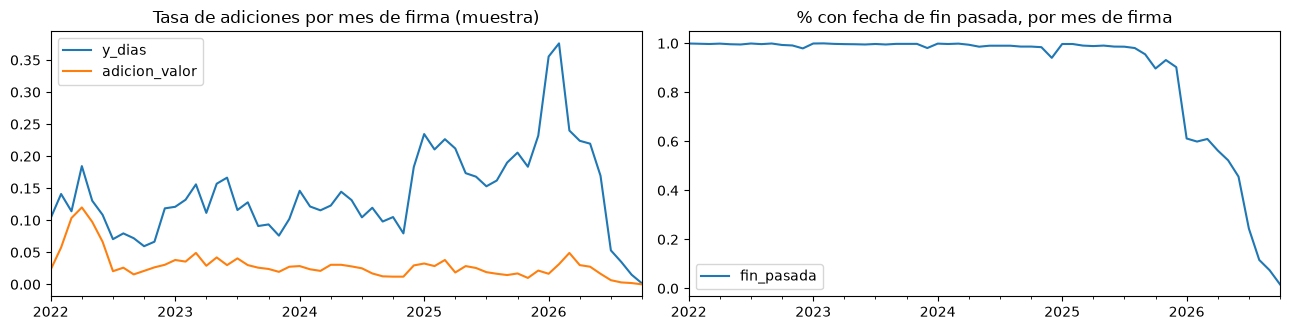

Dentro de 2025-26: contratos que ya terminaron vs vigentes


n  tasa_y_dias  tasa_adicion_valor
anio fin_pasada                                        
2025 False         795        0.605               0.026
     True        23205        0.182               0.022
2026 False       12377        0.140               0.015
     True         7623        0.216               0.024

Tasa de y_dias por modalidad y anio (grupos con >= 500 contratos):


anio,2023,2024,2025,2026
modalidad_de_contratacion,,,,
Contratación directa,0.117,0.099,0.178,0.104
Contratación régimen especial,0.139,0.218,0.247,0.278
Mínima cuantía,0.078,0.082,0.140,0.144
Selección Abreviada de Menor Cuantía,NaN,NaN,NaN,0.225


In [15]:
mensual = cen[cen.anio >= 2022].groupby("mes").agg(y_dias=("y_dias", "mean"), adicion_valor=("y_adic_valor", "mean"),
                                                    fin_pasada=("fin_pasada", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
mensual[["y_dias", "adicion_valor"]].plot(ax=ax[0]); ax[0].set_title("Tasa de adiciones por mes de firma (muestra)")
mensual[["fin_pasada"]].plot(ax=ax[1]); ax[1].set_title("% con fecha de fin pasada, por mes de firma")
for ax_ in ax:
    ax_.set_xlabel("")
plt.tight_layout(); plt.show()

rec = cen[cen.anio >= 2025]
print("Dentro de 2025-26: contratos que ya terminaron vs vigentes")
display(rec.groupby(["anio", "fin_pasada"]).agg(n=("id_contrato", "size"), tasa_y_dias=("y_dias", "mean"),
                                                tasa_adicion_valor=("y_adic_valor", "mean")).round(3))
comp = cen[cen.anio.between(2023, 2026)].groupby(["anio", "modalidad_de_contratacion"]).agg(n=("id_contrato", "size"), tasa=("y_dias", "mean"))
comp = comp[comp.n >= 500].round(3).reset_index().pivot(index="modalidad_de_contratacion", columns="anio", values="tasa")
print("Tasa de y_dias por modalidad y anio (grupos con >= 500 contratos):")
display(comp)

**Lectura de la censura**:

- **Regla aplicada: el año de test es 2025.** Es el más reciente con ≥ 90 % de contratos con fecha de fin pasada (97 % en la muestra y 97 % en la población; con un margen de 90 días sigue en 93,5 %). 2026 se excluye: solo 38 % (muestra) / 43 % (población) ha terminado.
- **[VERIFICADO] La tasa de adiciones sube, no cae, en los años recientes**: `y_dias` pasa de ~12 % (2023-24) a 20 % en 2025 en la población. El salto aparece en todas las modalidades (directa 10 -> 18 %, mínima cuantía 8 -> 14 %), así que no es un cambio de composición. **[SUPUESTO]** es un cambio en cómo se diligencia el campo o en las prácticas de contratación; no se pudo verificar la causa.
- **[VERIFICADO] "Fecha de fin pasada" no es independiente de la etiqueta**: los 795 contratos de 2025 que aún no terminaron tienen 60 % de adición, porque la prórroga misma retrasa la fecha de fin. Como esa columna ya incluye las prórrogas, el % de contratos terminados es una cota optimista de qué tan definitiva es la etiqueta.
- **Consecuencia**: 2025 cumple la regla, pero es un año atípico (tasa base 19,6 % frente a 11,2 % en el train). En la tabla de estabilidad del baseline se muestran también 2021-2024 como test.
- Las tasas por año de la muestra pesan igual a cada mes (2.000 por mes) y por eso difieren algo de las de la población (p. ej. 2026: 17 % vs 24 %); para niveles hay que mirar las de la población.

## 7. Inventario de features

Clasificación automática de las columnas de Contratos y de las de Procesos ya deduplicadas (prefijo `p_`): tipo, % de nulos y cardinalidad.

In [16]:
ids_cols = {"id_contrato", "proceso_de_compra", "referencia_del_contrato", "urlproceso", "p_id_del_proceso", "p_id_del_portafolio"}
texto_cols = {"objeto_del_contrato", "descripcion_del_proceso", "p_nombre_del_procedimiento", "descripcion_documentos_tipo",
              "justificacion_modalidad_de", "condiciones_de_entrega"}
inv = []
for c in [c for c in d.columns if c in contratos.columns or c.startswith("p_")]:
    if c in {"anio", "mes"}:
        continue
    s = d[c]
    if c in ids_cols:
        tipo = "id (no usar)"
    elif c in texto_cols:
        tipo = "texto libre"
    elif pd.api.types.is_datetime64_any_dtype(s):
        tipo = "fecha"
    elif pd.api.types.is_numeric_dtype(s):
        tipo = "numerica"
    else:
        nun = s.nunique()
        tipo = "categorica (<= 50)" if nun <= 50 else ("categorica (51-1000)" if nun <= 1000 else "categorica (> 1000)")
    inv.append({"columna": c, "tipo": tipo, "pct_nulos": round(s.isna().mean() * 100, 1), "n_unicos": s.nunique()})
inv = pd.DataFrame(inv)
display(inv.groupby("tipo").size().to_frame("n_columnas"))
display(inv.sort_values(["tipo", "columna"]).reset_index(drop=True))
print("Constantes (1 solo valor):", inv[inv.n_unicos <= 1].columna.tolist())
print(">= 95% nulos:", inv[inv.pct_nulos >= 95].columna.tolist())

,n_columnas
tipo,
categorica (51-1000),2
categorica (<= 50),35
categorica (> 1000),6
fecha,13
id (no usar),6
numerica,32
texto libre,6


,columna,tipo,pct_nulos,n_unicos
0,ciudad,categorica (51-1000),0.0,704
1,localizaci_n,categorica (51-1000),0.0,848
2,criterios_ambientales_en_la_evaluaci_n_de_las_ofertas,categorica (<= 50),0.0,3
3,criterios_de_sostenibilidad_ambiental,categorica (<= 50),0.0,3
4,departamento,categorica (<= 50),0.0,34
...,...,...,...,...
95,descripcion_del_proceso,texto libre,0.0,173375
96,descripcion_documentos_tipo,texto libre,0.0,17
97,justificacion_modalidad_de,texto libre,0.0,43
98,objeto_del_contrato,texto libre,0.0,175253


Constantes (1 solo valor): ['p_proveedores_que_manifestaron', 'p_subtipo_de_contrato']
>= 95% nulos: ['fecha_inicio_obligaciones_posconsumo', 'fecha_fin_obligaciones_posconsumo', 'fecha_inicio_reversi_n', 'fecha_fin_reversi_n']


## 8. Lista de fuga de información

Primero se verifican con datos las dos sospechas principales: que `fecha_de_fin_del_contrato` y `valor_del_contrato` ya incluyan las adiciones.

In [17]:
print("unidad_de_duracion del proceso:", d.p_unidad_de_duracion.value_counts().head(8).to_dict())
factor = d.p_unidad_de_duracion.fillna("").str.lower().str[0].map({"d": 1, "m": 30, "a": 365, "s": 7})
d["p_dur_dias"] = d.p_duracion * factor
d["dur_contrato_dias"] = (d.fecha_de_fin_del_contrato - d.fecha_de_inicio_del_contrato).dt.days

ok = d[d.anio.between(2019, ANIO_TEST) & d.p_dur_dias.between(1, 3650) & d.dur_contrato_dias.between(1, 3650)].copy()
ok["razon_dur"] = ok.dur_contrato_dias / ok.p_dur_dias
print("\nduracion del contrato (fin - inicio) / duracion planificada en el proceso, por y_dias:")
display(ok.groupby("y_dias").razon_dur.describe(percentiles=[.25, .5, .75]).round(2))

ok2 = d[d.anio.between(2019, ANIO_TEST) & d.p_precio_base.gt(0)].copy()
ok2["razon_valor"] = ok2.valor_del_contrato / ok2.p_precio_base
print("valor del contrato / precio base del proceso, por y_adic_valor:")
display(ok2.groupby("y_adic_valor").razon_valor.describe(percentiles=[.25, .5, .75]).round(3))

unidad_de_duracion del proceso: {'día(s)': 117915, 'Mes(es)': 91984, 'Año(s)': 1145, 'Hora(s)': 342, 'Semana(s)': 236, 'No Especificado': 5}



duracion del contrato (fin - inicio) / duracion planificada en el proceso, por y_dias:


,count,mean,std,min,25%,50%,75%,max
y_dias,,,,,,,,
0,136676.0,1.25,2.93,0.00,0.95,1.00,1.02,288.0
1,19687.0,2.59,5.16,0.02,1.21,1.44,2.01,221.8


valor del contrato / precio base del proceso, por y_adic_valor:


,count,mean,std,min,25%,50%,75%,max
y_adic_valor,,,,,,,,
0,156177.0,3522.579,1360081.815,0.0,1.0,1.000,1.000,537370000.0
1,9839.0,4195.392,304784.873,0.0,1.0,1.178,1.467,26250000.0


In [18]:
# AUC univariado (2019 hasta el anio de test) de columnas sospechosas: si una sola columna separa mucho, probablemente es fuga
from sklearn.metrics import roc_auc_score

d["dias_firma_a_ult_actualizacion"] = (d.ultima_actualizacion - d.fecha_de_firma).dt.days
sosp = ["valor_facturado", "valor_pagado", "valor_pendiente_de_pago", "valor_pendiente_de_ejecucion", "saldo_cdp",
        "saldo_vigencia", "dur_contrato_dias", "dias_firma_a_ult_actualizacion", "valor_del_contrato", "avance_real_max"]
base = d[d.anio.between(2019, ANIO_TEST)]
filas = []
for col in sosp:
    s = base[[col, "y_dias"]].dropna()
    filas.append({"columna": col, "n": len(s), "pct_nulos": round(base[col].isna().mean() * 100, 1),
                  "AUC_y_dias": round(roc_auc_score(s.y_dias, s[col]), 3) if s.y_dias.nunique() > 1 else np.nan})
for col in ["estado_contrato", "liquidaci_n"]:
    te = base.groupby(col).y_dias.transform("mean")
    filas.append({"columna": col + " (media por categoria, in-sample)", "n": len(base), "pct_nulos": round(base[col].isna().mean() * 100, 1),
                  "AUC_y_dias": round(roc_auc_score(base.y_dias, te), 3)})
display(pd.DataFrame(filas))
print("estado_contrato:", d.estado_contrato.value_counts().head(8).to_dict())

,columna,n,pct_nulos,AUC_y_dias
0,valor_facturado,167997,0.0,0.512
1,valor_pagado,167997,0.0,0.483
2,valor_pendiente_de_pago,167997,0.0,0.632
3,valor_pendiente_de_ejecucion,167997,0.0,0.632
4,saldo_cdp,167997,0.0,0.523
5,saldo_vigencia,167997,0.0,0.513
6,dur_contrato_dias,166262,1.0,0.711
7,dias_firma_a_ult_actualizacion,114230,32.0,0.258
8,valor_del_contrato,167997,0.0,0.641
9,avance_real_max,21059,87.5,0.468


estado_contrato: {'Cerrado': 66343, 'En ejecución': 51580, 'Modificado': 40431, 'terminado': 31639, 'Aprobado': 21035, 'cedido': 704, 'Suspendido': 240, 'En aprobación': 14}


In [19]:
fuga = pd.DataFrame([
    ("dias_adicionados", "ES la etiqueta A."),
    ("n_eventos, n_adic_valor, n_extension, n_mod_general, n_otros, primer_evento, ultimo_evento", "Vienen de Adiciones: son la etiqueta B o eventos posteriores a la firma."),
    ("estado_contrato", "Estado final (terminado, cerrado, liquidado, cancelado...); solo se conoce al final."),
    ("liquidaci_n, fecha_inicio_liquidacion, fecha_fin_liquidacion", "La liquidacion ocurre despues de terminar el contrato."),
    ("valor_facturado, valor_pagado, valor_pendiente_de_pago, valor_amortizado, valor_pendiente_de, valor_pendiente_de_ejecucion", "Acumulados de la ejecucion a la fecha de la consulta."),
    ("saldo_cdp, saldo_vigencia", "Saldos presupuestales que cambian durante la ejecucion."),
    ("fecha_de_fin_del_contrato y lo derivado (duracion fin - inicio)", "Se actualiza con las prorrogas: el cociente con la duracion planificada es mayor en los contratos con adicion (tabla de la seccion 8)."),
    ("valor_del_contrato", "[SUPUESTO] Puede incluir adiciones de valor; ver el cociente valor/precio base en la tabla de la seccion 8. Se evalua con y sin esta columna en el baseline."),
    ("fecha_de_notificaci_n_de_prorrogaci_n", "Es la fecha de una prorroga: posterior a la firma por definicion."),
    ("ultima_actualizacion", "Fecha de la ultima edicion del registro: mas ediciones = mas modificaciones."),
    ("reversion, fecha_inicio_reversi_n, fecha_fin_reversi_n, fechas de obligaciones posconsumo", "Eventos posteriores a la ejecucion."),
    ("Dataset Ejecucion completo (n_filas_ejec, avance_real_max, entregas, cantidades recibidas)", "Describe lo que pasa durante la ejecucion; ademas cubre solo 12,6 % de los contratos (seccion 4c)."),
    ("Dataset Modificaciones completo", "Son los eventos que definen la etiqueta."),
    ("p_estado_del_procedimiento, p_estado_resumen, p_fase", "Estado actual del proceso (se actualiza hasta el final); no es el estado al firmar."),
    ("p_valor_adjudicado_max, p_n_filas", "Con varios lotes/proveedores no es el valor del contrato; no se usan por ambiguedad."),
], columns=["columnas", "por que NO se pueden usar como feature"])
display(fuga)

,columnas,por que NO se pueden usar como feature
0,dias_adicionados,ES la etiqueta A.
1,"n_eventos, n_adic_valor, n_extension, n_mod_general, n_otros, primer_evento, ultimo_evento",Vienen de Adiciones: son la etiqueta B o eventos posteriores a la firma.
2,estado_contrato,"Estado final (terminado, cerrado, liquidado, cancelado...); solo se conoce al final."
3,"liquidaci_n, fecha_inicio_liquidacion, fecha_fin_liquidacion",La liquidacion ocurre despues de terminar el contrato.
4,"valor_facturado, valor_pagado, valor_pendiente_de_pago, valor_amortizado, valor_pendiente_de, valor_pendiente_de_eje...",Acumulados de la ejecucion a la fecha de la consulta.
5,"saldo_cdp, saldo_vigencia",Saldos presupuestales que cambian durante la ejecucion.
6,fecha_de_fin_del_contrato y lo derivado (duracion fin - inicio),Se actualiza con las prorrogas: el cociente con la duracion planificada es mayor en los contratos con adicion (tabla...
7,valor_del_contrato,[SUPUESTO] Puede incluir adiciones de valor; ver el cociente valor/precio base en la tabla de la seccion 8. Se evalu...
8,fecha_de_notificaci_n_de_prorrogaci_n,Es la fecha de una prorroga: posterior a la firma por definicion.
9,ultima_actualizacion,Fecha de la ultima edicion del registro: mas ediciones = mas modificaciones.


**Evidencia de fuga** (muestra, 2019-2025):

- **`fecha_de_fin_del_contrato` incluye las prórrogas [VERIFICADO]**: la duración real (fin - inicio) sobre la planificada en el proceso tiene mediana 1,00 sin adición y 1,44 con adición. Su AUC univariado es 0,71.
- **`valor_del_contrato` incluye adiciones de valor [VERIFICADO]**: sobre el precio base del proceso, la mediana es 1,00 sin adición de valor y 1,18 con ella (el 75 % de los positivos está en 1,47 o más). Es una fuga parcial: la mayoría de los contratos (sin adición) conserva su valor inicial.
- **`estado_contrato` es la fuga más fuerte [VERIFICADO]**: promediar `y_dias` por categoría ya da AUC 0,94 (in-sample), porque `Modificado` es un estado final.
- `valor_pendiente_de_pago` / `valor_pendiente_de_ejecucion` (AUC 0,63) y `ultima_actualizacion` (AUC 0,74 invertido) también separan, como era de esperar de columnas posteriores a la firma.
- `valor_facturado`, `valor_pagado`, `saldo_*` separan poco por sí solos (AUC 0,48-0,52), pero se descartan igual: son acumulados de la ejecución.

**Features seguras** (se conocen al firmar o antes): tipo y modalidad del contrato, entidad (sector, orden, departamento, NIT), categoría UNSPSC, `es_pyme`/`es_grupo`, pago adelantado habilitado, origen y destino del gasto, mezcla de fuentes de recursos, fechas de firma e inicio, longitud del objeto; y, del proceso, duración y precio base planificados, oferentes, invitados, lotes y fecha de publicación.

## 9. Baseline temporal

- Split **temporal**: entrena con años anteriores (desde 2019, porque en 2018 `dias_adicionados` casi no se diligenciaba) y prueba en `ANIO_TEST`. Los años posteriores quedan fuera.
- `HistGradientBoostingClassifier` con hiperparámetros por defecto (salvo `random_state`). Sin ajuste.
- Categóricas con codificación ordinal; las de alta cardinalidad se limitan a las 200 más frecuentes del train.
- Variantes: **A** solo features seguras de Contratos (la principal), **B** A + `valor_del_contrato`, **C** A + features seguras de Procesos, **D** con fuga (A + columnas posteriores a la firma, incluida Ejecución), para ver cuánto inflan las métricas.

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import OrdinalEncoder

d["mes_firma"] = d.fecha_de_firma.dt.month
d["dia_semana"] = d.fecha_de_firma.dt.dayofweek
d["dias_firma_a_inicio"] = (d.fecha_de_inicio_del_contrato - d.fecha_de_firma).dt.days.clip(-365, 365)
d["dias_publicacion_a_firma"] = (d.fecha_de_firma - d.p_fecha_de_publicacion_del).dt.days.clip(-30, 1000)
d["len_objeto"] = d.objeto_del_contrato.fillna("").str.len()
d["log_valor_contrato"] = np.log1p(d.valor_del_contrato.clip(lower=0))
d["log_precio_base"] = np.log1p(d.p_precio_base.clip(lower=0))
d["log_pago_adelantado"] = np.log1p(d.valor_de_pago_adelantado.clip(lower=0))
d["unspsc_6"] = d.codigo_de_categoria_principal.fillna("").str[:6]
d["fin_pasada"] = d.fecha_de_fin_del_contrato.between("2000-01-01", FECHA_CORTE)

CAT_C = ["tipo_de_contrato", "modalidad_de_contratacion", "sector", "orden", "rama", "entidad_centralizada", "departamento",
         "ciudad", "nit_entidad", "es_grupo", "es_pyme", "habilita_pago_adelantado", "origen_de_los_recursos",
         "destino_gasto", "espostconflicto", "el_contrato_puede_ser_prorrogado", "documentos_tipo", "tipodocproveedor", "unspsc_6"]
NUM_C = ["log_pago_adelantado", "mes_firma", "dia_semana", "dias_firma_a_inicio", "len_objeto",
         "presupuesto_general_de_la_nacion_pgn", "sistema_general_de_participaciones", "sistema_general_de_regal_as",
         "recursos_propios_alcald_as_gobernaciones_y_resguardos_ind_genas_", "recursos_de_credito", "recursos_propios"]
CAT_P = ["p_unidad_de_duracion"]
NUM_P = ["log_precio_base", "p_dur_dias", "p_numero_de_lotes", "p_proveedores_invitados", "p_proveedores_con_invitacion",
         "p_visualizaciones_del", "p_respuestas_al_procedimiento",
         "p_conteo_de_respuestas_a_ofertas", "p_proveedores_unicos_con", "dias_publicacion_a_firma"]
NUM_FUGA = ["dur_contrato_dias", "log_valor_contrato", "valor_pagado", "valor_facturado", "dias_firma_a_ult_actualizacion",
            "n_filas_ejec", "avance_real_max"]
CAT_FUGA = ["estado_contrato", "liquidaci_n"]

VARIANTES = {
    "A_contratos_seguras": (CAT_C, NUM_C),
    "B_A_mas_valor_contrato": (CAT_C, NUM_C + ["log_valor_contrato"]),
    "C_A_mas_procesos": (CAT_C + CAT_P, NUM_C + NUM_P),
    "D_CON_fuga": (CAT_C + CAT_FUGA, NUM_C + NUM_FUGA),
}


def preparar(tr, te, cat, num, top=200):
    Xtr, Xte = tr[num].copy(), te[num].copy()
    for c in cat:
        s_tr, s_te = tr[c].astype("string"), te[c].astype("string")
        frecuentes = s_tr.value_counts().head(top).index
        a_ = s_tr.where(s_tr.isin(frecuentes), "__otros__").fillna("__nan__").to_frame()
        b_ = s_te.where(s_te.isin(frecuentes), "__otros__").fillna("__nan__").to_frame()
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(a_)
        Xtr[c] = enc.transform(a_)[:, 0]
        Xte[c] = enc.transform(b_)[:, 0]
    Xte[cat] = Xte[cat].replace(-1, np.nan)
    return Xtr, Xte, [c in cat for c in Xtr.columns]


def baseline(y, anio_test, variante="A_contratos_seguras", anio_ini=2019):
    cat, num = VARIANTES[variante]
    tr = d[(d.anio >= anio_ini) & (d.anio < anio_test) & d[y].notna()]
    te = d[(d.anio == anio_test) & d[y].notna()]
    Xtr, Xte, mask = preparar(tr, te, cat, num)
    t0 = time.perf_counter()
    m = HistGradientBoostingClassifier(categorical_features=mask, random_state=SEED).fit(Xtr, tr[y])
    seg = time.perf_counter() - t0
    p = m.predict_proba(Xte)[:, 1]
    mi = proc.memory_info()
    res = {"objetivo": y, "variante": variante, "test": anio_test, "n_train": len(tr), "n_test": len(te),
           "tasa_base_train": tr[y].mean(), "tasa_base_test": te[y].mean(),
           "ROC_AUC": roc_auc_score(te[y], p), "PR_AUC": average_precision_score(te[y], p),
           "seg_entrenamiento": seg, "RAM_actual_MB": mi.rss / 1e6, "RAM_pico_MB": getattr(mi, "peak_wset", mi.rss) / 1e6}
    return res, m, Xte, te[y]


print("ANIO_TEST =", ANIO_TEST, "| train: 2019 a", ANIO_TEST - 1)
t_total = time.perf_counter()
resultados, modelos = [], {}
for variante in VARIANTES:
    objs = ["y_dias", "y_adic_valor", "y_cualquiera"] if variante == "A_contratos_seguras" else ["y_dias", "y_adic_valor"]
    for y in objs:
        r, m, Xte, yte = baseline(y, ANIO_TEST, variante)
        resultados.append(r)
        modelos[(variante, y)] = (m, Xte, yte)
        print(f"  listo {variante} / {y}: ROC {r['ROC_AUC']:.3f} PR {r['PR_AUC']:.3f} ({r['seg_entrenamiento']:.0f} s)")
res_tab = pd.DataFrame(resultados).set_index(["objetivo", "variante"])
display(res_tab.round(3))
print(f"tiempo total de los {len(resultados)} entrenamientos + codificacion: {time.perf_counter() - t_total:.0f} s")
ram("tras el baseline")

ANIO_TEST = 2025 | train: 2019 a 2024


  listo A_contratos_seguras / y_dias: ROC 0.727 PR 0.427 (2 s)


  listo A_contratos_seguras / y_adic_valor: ROC 0.853 PR 0.289 (2 s)


  listo A_contratos_seguras / y_cualquiera: ROC 0.733 PR 0.452 (2 s)


  listo B_A_mas_valor_contrato / y_dias: ROC 0.737 PR 0.427 (2 s)


...

  listo C_A_mas_procesos / y_adic_valor: ROC 0.861 PR 0.285 (2 s)


  listo D_CON_fuga / y_dias: ROC 0.948 PR 0.836 (2 s)


  listo D_CON_fuga / y_adic_valor: ROC 0.902 PR 0.330 (2 s)


,,test,n_train,n_test,tasa_base_train,tasa_base_test,ROC_AUC,PR_AUC,seg_entrenamiento,RAM_actual_MB,RAM_pico_MB
objetivo,variante,,,,,,,,,,
y_dias,A_contratos_seguras,2025,143997,24000,0.112,0.196,0.727,0.427,1.572,4107.293,4193.063
y_adic_valor,A_contratos_seguras,2025,143997,24000,0.065,0.022,0.853,0.289,1.533,4111.700,4197.782
y_cualquiera,A_contratos_seguras,2025,143997,24000,0.167,0.210,0.733,0.452,1.545,4225.823,4311.519
y_dias,B_A_mas_valor_contrato,2025,143997,24000,0.112,0.196,0.737,0.427,1.652,4120.711,4311.519
y_adic_valor,B_A_mas_valor_contrato,2025,143997,24000,0.065,0.022,0.856,0.301,1.701,4138.136,4311.519
y_dias,C_A_mas_procesos,2025,143997,24000,0.112,0.196,0.787,0.522,1.733,4159.341,4311.519
y_adic_valor,C_A_mas_procesos,2025,143997,24000,0.065,0.022,0.861,0.285,1.880,4163.551,4311.519
y_dias,D_CON_fuga,2025,143997,24000,0.112,0.196,0.948,0.836,1.763,4170.342,4311.519
y_adic_valor,D_CON_fuga,2025,143997,24000,0.065,0.022,0.902,0.330,1.796,4289.987,4399.317


tiempo total de los 9 entrenamientos + codificacion: 32 s
[RAM] tras el baseline: actual 3780 MB | pico 4399 MB


In [21]:
# estabilidad: variante A, y_dias, con distintos anios de test (entrena con 2019 hasta el anio anterior)
rolling = pd.DataFrame([baseline("y_dias", a_)[0] for a_ in range(2021, ANIO_TEST + 1)]).set_index("test")
display(rolling[["n_train", "n_test", "tasa_base_train", "tasa_base_test", "ROC_AUC", "PR_AUC", "seg_entrenamiento"]].round(3))

,n_train,n_test,tasa_base_train,tasa_base_test,ROC_AUC,PR_AUC,seg_entrenamiento
test,,,,,,,
2021,48000,24000,0.111,0.100,0.731,0.233,0.613
2022,72000,23998,0.107,0.104,0.763,0.344,0.740
2023,95998,24000,0.106,0.121,0.732,0.296,0.952
2024,119998,23999,0.109,0.123,0.763,0.334,1.446
2025,143997,24000,0.112,0.196,0.727,0.427,1.529


In [22]:
# importancia por permutacion (variante A, y_dias, 20.000 filas de test)
from sklearn.inspection import permutation_importance

m, Xte, yte = modelos[("A_contratos_seguras", "y_dias")]
idx = np.random.default_rng(SEED).choice(len(Xte), size=min(20000, len(Xte)), replace=False)
pi = permutation_importance(m, Xte.iloc[idx], yte.iloc[idx], scoring="roc_auc", n_repeats=3, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
display(imp.head(12).round(4).to_frame("caida de ROC-AUC al permutar"))

,caida de ROC-AUC al permutar
nit_entidad,0.0771
recursos_propios_alcald_as_gobernaciones_y_resguardos_ind_genas_,0.0252
recursos_propios,0.0191
presupuesto_general_de_la_nacion_pgn,0.0136
ciudad,0.0129
tipo_de_contrato,0.0106
dias_firma_a_inicio,0.0083
mes_firma,0.0071
sistema_general_de_participaciones,0.0057
unspsc_6,0.0056


**Lectura del baseline** (test = 2025, train = 2019-2024; sin ajuste de hiperparámetros):

- **`y_dias`, variante A (solo Contratos, seguras): ROC-AUC 0,73, PR-AUC 0,43 con tasa base 0,196.** Hay señal moderada: el PR-AUC es ~2,2 veces la tasa base. Agregar features de Procesos (C) sube a 0,79 / 0,52. Agregar `valor_del_contrato` (B) casi no cambia (0,74 / 0,43) y es una fuga parcial.
- **La fuga infla mucho** (variante D): `y_dias` pasa de ROC 0,73 a **0,95** y de PR 0,43 a **0,84**. Un resultado así en el proyecto final sería un espejismo.
- **Estabilidad**: con test 2021-2024 el ROC-AUC va de 0,73 a 0,76. El PR-AUC depende de la tasa base de cada año.
- **`y_adic_valor`**: ROC-AUC 0,85 pero PR-AUC 0,29 sobre una tasa base de 2,2 % (y 6,5 % en el train). Además la etiqueta no es estacionaria (sección 5), así que este número no es confiable como señal del comportamiento del contrato.
- **Qué aprende el modelo**: la feature más importante por mucho es `nit_entidad` (caída de 0,077 de ROC-AUC al permutarla); le siguen las fuentes de recursos y la ciudad. Es decir, aprende en buena parte el **hábito de cada entidad**. Es información legítima al firmar, pero no generaliza a entidades nuevas, y no se midió aquí.
- **Costo**: cada entrenamiento tarda ~1-2 s (`HistGradientBoostingClassifier` con early stopping automático, que reserva internamente un 10 % aleatorio del train). Los 9 entrenamientos más la codificación tardan ~25 s. El pico de RAM del proceso, con todos los DataFrames cargados, fue ~4,3 GB (< 6 GB).

## 10. Resumen para el checkpoint

In [23]:
print("1) Tasas de etiqueta por anio de firma y % de contratos con fecha de fin pasada (muestra):")
display(tabla_cen[["n_muestra", "tasa_y_dias_tiempo", "tasa_adicion_valor", "tasa_mod_general", "tasa_otros_eventos",
                   "pct_fin_pasada_muestra", "pct_fin_pasada_POBLACION"]].round(3))
print("2) Anio de test:", ANIO_TEST)
print("3) Baseline (ROC-AUC, PR-AUC, tasa base del test):")
display(res_tab[["n_train", "n_test", "tasa_base_test", "ROC_AUC", "PR_AUC", "seg_entrenamiento"]].round(3))
ram("final")

1) Tasas de etiqueta por anio de firma y % de contratos con fecha de fin pasada (muestra):


,n_muestra,tasa_y_dias_tiempo,tasa_adicion_valor,tasa_mod_general,tasa_otros_eventos,pct_fin_pasada_muestra,pct_fin_pasada_POBLACION
anio,,,,,,,
2018,24000,0.008,0.161,0.373,0.495,0.999,0.999
2019,24000,0.093,0.182,0.417,0.567,0.999,1.000
2020,24000,0.128,0.068,0.404,0.642,0.999,0.999
2021,24000,0.100,0.033,0.365,0.678,0.997,0.998
2022,23998,0.104,0.051,0.397,0.652,0.995,0.997
2023,24000,0.121,0.033,0.354,0.592,0.996,0.996
2024,23999,0.123,0.023,0.342,0.585,0.987,0.990
2025,24000,0.196,0.022,0.348,0.447,0.967,0.972
2026,20000,0.169,0.018,0.228,0.078,0.381,0.432


2) Anio de test: 2025
3) Baseline (ROC-AUC, PR-AUC, tasa base del test):


,,n_train,n_test,tasa_base_test,ROC_AUC,PR_AUC,seg_entrenamiento
objetivo,variante,,,,,,
y_dias,A_contratos_seguras,143997,24000,0.196,0.727,0.427,1.572
y_adic_valor,A_contratos_seguras,143997,24000,0.022,0.853,0.289,1.533
y_cualquiera,A_contratos_seguras,143997,24000,0.210,0.733,0.452,1.545
y_dias,B_A_mas_valor_contrato,143997,24000,0.196,0.737,0.427,1.652
y_adic_valor,B_A_mas_valor_contrato,143997,24000,0.022,0.856,0.301,1.701
y_dias,C_A_mas_procesos,143997,24000,0.196,0.787,0.522,1.733
y_adic_valor,C_A_mas_procesos,143997,24000,0.022,0.861,0.285,1.880
y_dias,D_CON_fuga,143997,24000,0.196,0.948,0.836,1.763
y_adic_valor,D_CON_fuga,143997,24000,0.022,0.902,0.330,1.796


[RAM] final: actual 3789 MB | pico 4399 MB


## 11. Regla simple "tasa histórica por entidad", entidades no vistas y HGB sin entidad

Sección añadida el 2026-10-15 (local, sin red). El baseline de la sección 9 dependía sobre todo de `nit_entidad`; aquí se mide cuánto de su señal ya captura una regla trivial y cuánto queda sin la identidad de la entidad.

- **Regla**: para cada `nit_entidad`, tasa de `y_dias` en el train, suavizada hacia la tasa global: `(positivos + m * p0) / (contratos + m)`, donde `p0` es la tasa global del train y `m` los "contratos virtuales" del prior. Score = esa tasa; las entidades que no aparecen en el train reciben `p0`.
- **Parámetro `m`**: se elige **sin tocar el test**, con una validación temporal dentro del train (entrena hasta el año T-2 y valida en T-1; ROC-AUC). Como contraste, se reporta el `m` implícito de un estimador ANOVA de la correlación intraclase (`m = (1 - rho) / rho`).
- **Tests**: 2024 (train 2019-2023, principal) y 2025 (train 2019-2024, deriva). Mismo HGB por defecto de la sección 9, así que las filas "HGB A" y "HGB C" deben reproducir esas cifras.
- **Cautela sobre "no vistas"**: la muestra es ~4 % de la población (hasta 2.000 contratos por mes), así que una entidad "no vista" en el train de la muestra puede tener contratos en el train completo. El porcentaje de entidades no vistas aquí sobreestima el que enfrentaría un modelo entrenado con todo.

In [24]:
from sklearn.metrics import roc_auc_score, average_precision_score

COL_ENT = "nit_entidad"
print("nit_entidad nulo:", int(d[COL_ENT].isna().sum()), "| entidades distintas en la muestra:", d[COL_ENT].nunique())


def metricas(y, s):
    y = np.asarray(y); s = np.asarray(s, dtype=float)
    out = {"n": len(y), "positivos": int(y.sum()), "tasa_base": y.mean(), "ROC_AUC": np.nan, "PR_AUC": np.nan, "PR/base": np.nan}
    if 0 < y.sum() < len(y) and len(y) >= 100:
        out["ROC_AUC"] = roc_auc_score(y, s)
        out["PR_AUC"] = average_precision_score(y, s)
        out["PR/base"] = out["PR_AUC"] / out["tasa_base"]
    return out


def regla_entidad(tr, te, m, top=None):
    p0 = tr.y_dias.mean()
    g = tr.groupby(COL_ENT).y_dias.agg(["sum", "count"])
    if top is not None:
        g = g.loc[g["count"].sort_values(ascending=False).head(top).index]
    tasa = (g["sum"] + m * p0) / (g["count"] + m)
    return te[COL_ENT].map(tasa).fillna(p0).to_numpy()


def icc_anova(tr):
    g = tr.groupby(COL_ENT).y_dias.agg(["sum", "count"])
    n, k = g["count"].to_numpy(float), g["sum"].to_numpy(float)
    E, N = len(n), n.sum()
    p, r = k.sum() / N, k / n
    msb = (n * (r - p) ** 2).sum() / (E - 1)
    msw = (n * r * (1 - r)).sum() / (N - E)
    n0 = (N - (n ** 2).sum() / N) / (E - 1)
    rho = (msb - msw) / (msb + (n0 - 1) * msw)
    return rho, (1 - rho) / rho


GRID_M = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500]


def elegir_m(anio_test):
    v = anio_test - 1
    tr = d[(d.anio >= 2019) & (d.anio < v)]
    va = d[d.anio == v]
    filas = []
    for m_ in GRID_M:
        mm = metricas(va.y_dias, regla_entidad(tr, va, m_))
        filas.append({"m": m_, "ROC_AUC_val": mm["ROC_AUC"], "PR_AUC_val": mm["PR_AUC"]})
    t = pd.DataFrame(filas)
    return t, int(t.loc[t.ROC_AUC_val.idxmax(), "m"])


M_ELEGIDO = {}
for T in (2024, 2025):
    t_m, M_ELEGIDO[T] = elegir_m(T)
    rho, m_icc = icc_anova(d[(d.anio >= 2019) & (d.anio < T)])
    print(f"\nTest {T}: validacion en {T - 1} (train 2019-{T - 2}). m elegido = {M_ELEGIDO[T]} | ANOVA: rho = {rho:.3f} -> m implicito = {m_icc:.1f}")
    display(t_m.round(4).set_index("m").T)

nit_entidad nulo: 0 | entidades distintas en la muestra: 2788



Test 2024: validacion en 2023 (train 2019-2022). m elegido = 0 | ANOVA: rho = 0.107 -> m implicito = 8.3


m,0,1,2,5,10,20,50,100,200,500
ROC_AUC_val,0.6520,0.6520,0.6502,0.6471,0.6446,0.6413,0.6361,0.6343,0.6318,0.6278
PR_AUC_val,0.2046,0.2071,0.2065,0.2048,0.2045,0.2038,0.2006,0.2003,0.1982,0.1960



Test 2025: validacion en 2024 (train 2019-2023). m elegido = 1 | ANOVA: rho = 0.106 -> m implicito = 8.4


m,0,1,2,5,10,20,50,100,200,500
ROC_AUC_val,0.7143,0.7150,0.7138,0.7117,0.7095,0.7058,0.7003,0.6962,0.6925,0.6887
PR_AUC_val,0.2773,0.2822,0.2858,0.2900,0.2923,0.2930,0.2933,0.2912,0.2928,0.2924


### 11a. HGB frente a la regla por entidad

In [25]:
VARIANTES["A_sin_nit"] = ([c for c in CAT_C if c != COL_ENT], NUM_C)
VARIANTES["C_sin_nit"] = ([c for c in CAT_C + CAT_P if c != COL_ENT], NUM_C + NUM_P)
GEO_ENT = {"nit_entidad", "sector", "orden", "rama", "entidad_centralizada", "departamento", "ciudad"}
VARIANTES["A_sin_entidad_ni_geo"] = ([c for c in CAT_C if c not in GEO_ENT], NUM_C)

MODELOS_HGB = [("HGB A (Contratos, seguras)", "A_contratos_seguras"), ("HGB C (A + Procesos)", "C_A_mas_procesos"),
               ("HGB A sin nit_entidad", "A_sin_nit"), ("HGB C sin nit_entidad", "C_sin_nit"),
               ("HGB A sin entidad ni geografia", "A_sin_entidad_ni_geo")]


def evaluar(T):
    tr = d[(d.anio >= 2019) & (d.anio < T)]
    te = d[d.anio == T]
    m_ = M_ELEGIDO[T]
    punt = {"Tasa base (constante)": np.full(len(te), tr.y_dias.mean()),
            f"Regla: tasa por entidad (m={m_})": regla_entidad(tr, te, m_),
            f"Regla: solo 200 entidades mas frecuentes (m={m_})": regla_entidad(tr, te, m_, top=200)}
    for nombre, var in MODELOS_HGB:
        r, mod, Xte, yte = baseline("y_dias", T, var)
        assert (Xte.index == te.index).all()
        punt[nombre] = mod.predict_proba(Xte)[:, 1]
    return tr, te, punt


EV = {}
for T in (2024, 2025):
    EV[T] = evaluar(T)
    tr, te, punt = EV[T]
    tabla = pd.DataFrame({k: metricas(te.y_dias, v) for k, v in punt.items()}).T
    print(f"\n=== Test {T} (train 2019-{T - 1}): n_train = {len(tr)}, n_test = {len(te)}, tasa base test = {te.y_dias.mean():.3f} ===")
    display(tabla[["ROC_AUC", "PR_AUC", "PR/base"]].astype(float).round(3))
    top200 = tr[COL_ENT].value_counts().head(200).sum() / len(tr)
    print(f"Las 200 entidades mas frecuentes concentran {top200:.1%} de los contratos del train (el HGB solo conoce esas por nombre).")


=== Test 2024 (train 2019-2023): n_train = 119998, n_test = 23999, tasa base test = 0.123 ===


,ROC_AUC,PR_AUC,PR/base
Tasa base (constante),0.500,0.123,1.000
Regla: tasa por entidad (m=0),0.714,0.277,2.261
Regla: solo 200 entidades mas frecuentes (m=0),0.670,0.268,2.184
"HGB A (Contratos, seguras)",0.763,0.334,2.726
HGB C (A + Procesos),0.809,0.436,3.555
HGB A sin nit_entidad,0.753,0.320,2.610
HGB C sin nit_entidad,0.825,0.441,3.594
HGB A sin entidad ni geografia,0.707,0.286,2.330


Las 200 entidades mas frecuentes concentran 71.6% de los contratos del train (el HGB solo conoce esas por nombre).



=== Test 2025 (train 2019-2024): n_train = 143997, n_test = 24000, tasa base test = 0.196 ===


,ROC_AUC,PR_AUC,PR/base
Tasa base (constante),0.500,0.196,1.000
Regla: tasa por entidad (m=1),0.646,0.341,1.743
Regla: solo 200 entidades mas frecuentes (m=1),0.621,0.321,1.640
"HGB A (Contratos, seguras)",0.727,0.427,2.178
HGB C (A + Procesos),0.787,0.522,2.666
HGB A sin nit_entidad,0.736,0.419,2.141
HGB C sin nit_entidad,0.800,0.509,2.597
HGB A sin entidad ni geografia,0.723,0.388,1.982


Las 200 entidades mas frecuentes concentran 70.0% de los contratos del train (el HGB solo conoce esas por nombre).


In [26]:
# Sensibilidad (informativa; NO se usa para elegir m): metricas de la regla en el test para toda la grilla de m, incluido el m implicito del ANOVA (~8).
filas = []
for T in (2024, 2025):
    tr, te, punt = EV[T]
    for m_ in GRID_M:
        mm = metricas(te.y_dias, regla_entidad(tr, te, m_))
        filas.append({"test": T, "m": m_, "ROC_AUC": mm["ROC_AUC"], "PR_AUC": mm["PR_AUC"]})
display(pd.DataFrame(filas).pivot(index="test", columns="m", values="ROC_AUC").round(3))
display(pd.DataFrame(filas).pivot(index="test", columns="m", values="PR_AUC").round(3))

m,0,1,2,5,10,20,50,100,200,500
test,,,,,,,,,,
2024,0.714,0.715,0.714,0.712,0.710,0.706,0.700,0.696,0.693,0.689
2025,0.646,0.646,0.646,0.644,0.643,0.642,0.639,0.637,0.635,0.633


m,0,1,2,5,10,20,50,100,200,500
test,,,,,,,,,,
2024,0.277,0.282,0.286,0.290,0.292,0.293,0.293,0.291,0.293,0.292
2025,0.338,0.341,0.344,0.346,0.346,0.347,0.346,0.346,0.346,0.352


In [27]:
# Diferencia HGB - regla con intervalo bootstrap (re-muestreo de contratos del test, 200 repeticiones). Los contratos de una misma entidad
# estan correlacionados, asi que el intervalo es optimista.
def boot_dif(y, s1, s0, B=200, seed=SEED):
    rng = np.random.default_rng(seed)
    y = np.asarray(y); n = len(y)
    dr, dp = [], []
    for _ in range(B):
        i = rng.integers(0, n, n)
        yy = y[i]
        dr.append(roc_auc_score(yy, s1[i]) - roc_auc_score(yy, s0[i]))
        dp.append(average_precision_score(yy, s1[i]) - average_precision_score(yy, s0[i]))
    return np.percentile(dr, [2.5, 97.5]), np.percentile(dp, [2.5, 97.5])


filas = []
for T in (2024, 2025):
    tr, te, punt = EV[T]
    ref = punt[f"Regla: tasa por entidad (m={M_ELEGIDO[T]})"]
    for nombre in ["HGB A (Contratos, seguras)", "HGB C (A + Procesos)"]:
        ci_r, ci_p = boot_dif(te.y_dias, punt[nombre], ref)
        mm_h, mm_r = metricas(te.y_dias, punt[nombre]), metricas(te.y_dias, ref)
        filas.append({"test": T, "modelo": nombre, "dif_ROC": mm_h["ROC_AUC"] - mm_r["ROC_AUC"], "IC95_ROC": f"[{ci_r[0]:+.3f}, {ci_r[1]:+.3f}]",
                      "dif_PR": mm_h["PR_AUC"] - mm_r["PR_AUC"], "IC95_PR": f"[{ci_p[0]:+.3f}, {ci_p[1]:+.3f}]"})
print("HGB menos regla por entidad:")
display(pd.DataFrame(filas).round(3))

HGB menos regla por entidad:


,test,modelo,dif_ROC,IC95_ROC,dif_PR,IC95_PR
0,2024,"HGB A (Contratos, seguras)",0.048,"[+0.041, +0.056]",0.057,"[+0.043, +0.072]"
1,2024,HGB C (A + Procesos),0.095,"[+0.087, +0.103]",0.159,"[+0.144, +0.174]"
2,2025,"HGB A (Contratos, seguras)",0.081,"[+0.075, +0.088]",0.085,"[+0.074, +0.095]"
3,2025,HGB C (A + Procesos),0.141,"[+0.134, +0.149]",0.181,"[+0.170, +0.193]"


### 11b. Entidades no vistas en el train

In [28]:
filas = []
for T in (2024, 2025):
    tr, te, punt = EV[T]
    cuenta = te[COL_ENT].map(tr[COL_ENT].value_counts()).fillna(0)
    grupos = {"NO vistas (0 contratos en train)": cuenta == 0, "1-9 contratos en train": cuenta.between(1, 9),
              "10-49 contratos en train": cuenta.between(10, 49), "50+ contratos en train": cuenta >= 50, "TODAS": cuenta >= 0}
    n_ent_te = te[COL_ENT].nunique()
    n_ent_nuevas = te.loc[cuenta == 0, COL_ENT].nunique()
    print(f"Test {T}: {int((cuenta == 0).sum())} de {len(te)} contratos ({(cuenta == 0).mean():.1%}) son de entidades no vistas; "
          f"{n_ent_nuevas} de {n_ent_te} entidades del test ({n_ent_nuevas / n_ent_te:.1%}) no aparecen en el train.")
    for gname, mask in grupos.items():
        for nombre, s in punt.items():
            if nombre.startswith("Regla: solo 200"):
                continue
            mm = metricas(te.y_dias[mask.values], s[mask.values])
            filas.append({"test": T, "grupo": gname, "modelo": nombre, **mm})
sub = pd.DataFrame(filas)
sub["modelo"] = sub.modelo.str.replace(r" \(m=\d+\)", "", regex=True)
for T in (2024, 2025):
    print(f"\n=== Test {T}: ROC-AUC por historial de la entidad en el train ===")
    x = sub[sub.test == T]
    display(x.pivot_table(index="grupo", columns="modelo", values="ROC_AUC", sort=False).round(3).join(
        x.drop_duplicates("grupo").set_index("grupo")[["n", "tasa_base"]].round(3)))
    print("PR_AUC / tasa base del grupo:")
    display(x.pivot_table(index="grupo", columns="modelo", values="PR/base", sort=False).round(2))

Test 2024: 804 de 23999 contratos (3.4%) son de entidades no vistas; 235 de 1638 entidades del test (14.3%) no aparecen en el train.
Test 2025: 1110 de 24000 contratos (4.6%) son de entidades no vistas; 276 de 1767 entidades del test (15.6%) no aparecen en el train.



=== Test 2024: ROC-AUC por historial de la entidad en el train ===


,Tasa base (constante),Regla: tasa por entidad,"HGB A (Contratos, seguras)",HGB C (A + Procesos),HGB A sin nit_entidad,HGB C sin nit_entidad,HGB A sin entidad ni geografia,n,tasa_base
grupo,,,,,,,,,
NO vistas (0 contratos en train),0.5,0.500,0.674,0.753,0.632,0.706,0.616,804,0.068
1-9 contratos en train,0.5,0.529,0.742,0.791,0.730,0.782,0.715,2306,0.048
10-49 contratos en train,0.5,0.647,0.684,0.758,0.686,0.761,0.675,3378,0.074
50+ contratos en train,0.5,0.719,0.760,0.808,0.747,0.829,0.704,17511,0.144
TODAS,0.5,0.714,0.763,0.809,0.753,0.825,0.707,23999,0.123


PR_AUC / tasa base del grupo:


modelo,Tasa base (constante),Regla: tasa por entidad,"HGB A (Contratos, seguras)",HGB C (A + Procesos),HGB A sin nit_entidad,HGB C sin nit_entidad,HGB A sin entidad ni geografia
grupo,,,,,,,
NO vistas (0 contratos en train),1.0,1.00,1.90,3.45,1.61,2.99,1.87
1-9 contratos en train,1.0,1.08,2.81,3.67,2.90,3.83,2.24
10-49 contratos en train,1.0,1.68,2.20,3.04,2.42,3.36,2.23
50+ contratos en train,1.0,2.24,2.52,3.26,2.40,3.30,2.22
TODAS,1.0,2.26,2.73,3.55,2.61,3.59,2.33



=== Test 2025: ROC-AUC por historial de la entidad en el train ===


,Tasa base (constante),Regla: tasa por entidad,"HGB A (Contratos, seguras)",HGB C (A + Procesos),HGB A sin nit_entidad,HGB C sin nit_entidad,HGB A sin entidad ni geografia,n,tasa_base
grupo,,,,,,,,,
NO vistas (0 contratos en train),0.5,0.500,0.790,0.810,0.791,0.824,0.771,1110,0.078
1-9 contratos en train,0.5,0.550,0.690,0.779,0.688,0.764,0.710,1771,0.129
10-49 contratos en train,0.5,0.588,0.688,0.775,0.685,0.758,0.694,3531,0.141
50+ contratos en train,0.5,0.655,0.722,0.783,0.732,0.801,0.716,17588,0.221
TODAS,0.5,0.646,0.727,0.787,0.736,0.800,0.723,24000,0.196


PR_AUC / tasa base del grupo:


modelo,Tasa base (constante),Regla: tasa por entidad,"HGB A (Contratos, seguras)",HGB C (A + Procesos),HGB A sin nit_entidad,HGB C sin nit_entidad,HGB A sin entidad ni geografia
grupo,,,,,,,
NO vistas (0 contratos en train),1.0,1.00,3.09,4.22,3.26,4.13,3.51
1-9 contratos en train,1.0,1.36,2.31,3.09,2.18,2.96,2.20
10-49 contratos en train,1.0,1.57,2.04,2.81,2.05,2.72,1.95
50+ contratos en train,1.0,1.70,2.05,2.48,2.01,2.41,1.87
TODAS,1.0,1.74,2.18,2.67,2.14,2.60,1.98


### 11c. Tabla comparativa final

In [29]:
filas = []
for T in (2024, 2025):
    tr, te, punt = EV[T]
    cuenta = te[COL_ENT].map(tr[COL_ENT].value_counts()).fillna(0).values
    for nombre, s in punt.items():
        mm = metricas(te.y_dias, s)
        mn = metricas(te.y_dias[cuenta == 0], s[cuenta == 0])
        filas.append({"test": T, "modelo": nombre.replace(f" (m={M_ELEGIDO[T]})", ""), "ROC_AUC": mm["ROC_AUC"], "PR_AUC": mm["PR_AUC"], "PR/base": mm["PR/base"],
                      "ROC_no_vistas": mn["ROC_AUC"], "PR/base_no_vistas": mn["PR/base"]})
final = pd.DataFrame(filas).set_index(["test", "modelo"])
display(final.astype(float).round(3))
ram("seccion 11")

ROC_AUC  PR_AUC  PR/base  ROC_no_vistas  PR/base_no_vistas
test modelo                                                                                              
2024 Tasa base (constante)                       0.500   0.123    1.000          0.500              1.000
     Regla: tasa por entidad                     0.714   0.277    2.261          0.500              1.000
     Regla: solo 200 entidades mas frecuentes    0.670   0.268    2.184          0.500              1.000
     HGB A (Contratos, seguras)                  0.763   0.334    2.726          0.674              1.897
     HGB C (A + Procesos)                        0.809   0.436    3.555          0.753              3.447
     HGB A sin nit_entidad                       0.753   0.320    2.610          0.632              1.611
     HGB C sin nit_entidad                       0.825   0.441    3.594          0.706              2.985
     HGB A sin entidad ni geografia              0.707   0.286    2.330          0.616              1.871
2025 Tasa base (constante)                       0.500   0.196    1.000          0.500              1.000
     Regla: tasa por entidad                     0.646   0.341    1.743          0.500              1.000
     Regla: solo 200 entidades mas frecuentes    0.621   0.321    1.640          0.500              1.000
     HGB A (Contratos, seguras)                  0.727   0.427    2.178          0.790              3.095
     HGB C (A + Procesos)                        0.787   0.522    2.666          0.810              4.219
     HGB A sin nit_entidad                       0.736   0.419    2.141          0.791              3.256
     HGB C sin nit_entidad                       0.800   0.509    2.597          0.824              4.130
     HGB A sin entidad ni geografia              0.723   0.388    1.982          0.771              3.515

[RAM] seccion 11: actual 4236 MB | pico 5166 MB
